# 信道轨迹生成：Sionna TDL-C + 几何大尺度

本 notebook 是 [sionna_traces.py](sionna_traces.py) 的**讲解版**，说明每条信道轨迹
$g_0,\dots,g_{T-1}$ 是如何从物理模型生成的。

## 架构约定（解耦）

信道建模**只在离线阶段运行一次**，产物是 `traces/*.npz`；
下游模块（env / baselines / 评估）**只读 npz，绝不 import sionna**。

$$\underbrace{\text{Sionna TDL}}_{\text{离线、重依赖}}
\;\longrightarrow\;
\boxed{\;g[N,T]\ \text{npz 文件}\;}
\;\longrightarrow\;
\underbrace{\text{env / 注水 / 策略}}_{\text{在线、纯 numpy}}$$

好处：信道模型的复杂性被"封存"在一个脚本里，下游代码轻量、可审计、可复现。

## 总增益模型

每时隙的**线性功率增益**是三部分相乘：

$$g_t = \underbrace{10^{-L_{\mathrm{fs}}(d_t)/10}}_{\text{大尺度：自由空间路损}}
\;\cdot\;
\underbrace{10^{\xi/10}}_{\text{阴影（轨迹内恒定）}}
\;\cdot\;
\underbrace{g_{\mathrm{small}}(t)}_{\text{小尺度：TDL-C 瑞利}}
,\qquad \xi\sim\mathcal N(0,\sigma_{\mathrm{sh}}^2)$$

| 组成 | 时间尺度 | 本脚本实现 |
|---|---|---|
| 自由空间路损 $L_{\mathrm{fs}}$ | 随 U 形距离慢变 | 解析公式 |
| 阴影 $\xi$ | 每条轨迹恒定（~1 s 内环境不变）| `rng.normal` 一次/轨迹 |
| 小尺度 $g_{\mathrm{small}}$ | 毫秒级快变 | **Sionna TDL-C** |

In [1]:
import os, sys, time
from dataclasses import replace
import numpy as np
from scipy.special import j0

# 基于 config.py 位置推导项目根，与启动目录（cwd）无关
sys.path.insert(0, os.path.abspath('..'))   # cwd=channel/ 时
from config import SceneConfig
import config as _cfg_mod
ROOT = os.path.dirname(os.path.abspath(_cfg_mod.__file__))
sys.path.insert(0, ROOT)

import matplotlib.pyplot as plt
import torch
import sionna
from sionna.phy import config as sionna_config
from sionna.phy.channel.tr38901 import TDL
from channel.trace_io import save_traces  # 两种 cwd 下都能导入

TRACE_DIR = os.path.join(ROOT, 'traces')
RESULT_DIR = os.path.join(ROOT, 'results')
CHUNK = 100
print('sionna', sionna.__version__, '| torch', torch.__version__)

sionna 2.2.0 | torch 2.11.0+cu128


## 1. 小尺度衰落：TDL-C 与窄带合成

### 1.1 TDL-C 是什么

3GPP TR 38.901 定义的 **Tapped Delay Line（抽头延迟线）**模型 C：
城市/郊区宏蜂窝 **NLoS 富散射**场景，RMS 时延扩展 $300$ ns。
信道冲激响应写成 $P$ 条路径之和：

$$h(\tau,t)=\sum_{p=1}^{P} a_p(t)\,\delta(\tau-\tau_p)$$

每个抽头 $a_p(t)$ 是一个**零均值复高斯随机过程**（幅度瑞利分布），
其时间相关性由多普勒决定，谱形为 **Jakes 谱**。

### 1.2 Sum-of-Sinusoids（SoS）生成器

Sionna 用有限个正弦波叠加逼近 Jakes 谱的随机过程：

$$a_p(t)=\sum_{n=1}^{N_{\mathrm{sos}}} c_{pn}\,
\exp\!\Big(j\big[2\pi f_D\cos\theta_{pn}\,t+\phi_{pn}\big]\Big)$$

- $f_D = v f_c/c$：最大多普勒频移
- $\theta_{pn}$：随机到达角，决定该正弦波的多普勒频率 $f_D\cos\theta$
- $\phi_{pn}$：随机初相
- $N_{\mathrm{sos}}=20$：实践中 16–32 个已足够逼近理论谱

### 1.3 窄带合成（关键一行代码）

本实验是**时域功率分配**，不研究频率选择性，因此把 $P$ 条路径
**相干相加**成一个复信道系数，再取模平方：

$$h_t=\sum_{p=1}^{P} a_p(t),\qquad g_{\mathrm{small}}(t)=|h_t|^2$$

> 物理依据：每个 15 kHz 子载波内信道频率平坦（$300\text{ ns}\ll 1/15\text{ kHz}\approx67\,\mu$s），
> 故可用一个标量 $g_t$ 代表该时隙的信道功率增益，且 $\mathbb E[g_{\mathrm{small}}]=1$。

### 1.4 功率增益的相关函数是 $J_0^2$，不是 $J_0$

这是一个高频易错点：

- **复信道系数** $h_t$ 的自相关：$\mathbb E[h_t h_{t+\tau}^*] = J_0(2\pi f_D \tau)$
- **功率增益** $g=|h|^2$ 的自相关（瑞利过程的平方律）：

$$\rho_g(\tau)=J_0^2(2\pi f_D \tau)$$

脚本生成轨迹后立即用经验 ACF 对拍 $J_0^2$ 理论曲线——这是整个
"速度→信道时变快慢"实验变量的正确性校验。

## 2. 大尺度：U 形几何 + FSPL + 阴影

### 2.1 U 形距离

车辆在笔直道路上匀速经过静止接收机（垂直偏移 $d_\perp=20$ m）：

$$x(t)=v\left(t-\frac{T-1}{2}\Delta t\right),\qquad
d(t)=\sqrt{d_\perp^2+x(t)^2}$$

### 2.2 自由空间路损（Friis）

$$L_{\mathrm{fs}}(d)=20\log_{10}\!\left(\frac{4\pi d f_c}{c}\right)\ \mathrm{dB},
\qquad g_{\mathrm{ls}}(t)=10^{-L_{\mathrm{fs}}(d(t))/10}$$

### 2.3 阴影

每条轨迹采样**一次** $\xi\sim\mathcal N(0,4^2)$ dB，对全部 $T$ 个时隙相同
（1 s 内车辆只移动 8–97 m，传播环境近似不变）。
阴影随机流用 `seed+1` 的独立 `np.random.Generator`，与 Sionna TDL 随机流隔离。

## 3. 单速度轨迹生成

下面的 `generate_speed` 逐批（`CHUNK=100`，控制 TDL 中间张量内存）生成
$n$ 条轨迹，并对第一批计算小尺度统计量。

In [2]:
def generate_speed(cfg, speed_kmh, n_traces, seed):
    d = cfg.distance_m(speed_kmh)                     # [T] U 形距离
    g_ls_time = 10.0 ** (-cfg.fspl_db(d) / 10.0)      # [T] 无阴影大尺度增益
    f_d = cfg.f_doppler(speed_kmh)

    # Sionna TDL：固定速度 → min_speed = max_speed（m/s，内部按载频换算多普勒）
    sionna_config.seed = seed
    sionna_config.device = 'cpu'
    tdl = TDL(model=cfg.tdl_profile,
              delay_spread=cfg.tdl_delay_spread_s,
              carrier_frequency=cfg.f_c_hz,
              num_sinusoids=cfg.num_sinusoids,
              min_speed=cfg.speed_to_mps(speed_kmh),
              max_speed=cfg.speed_to_mps(speed_kmh),
              device='cpu')

    rng = np.random.default_rng(seed + 1)             # 阴影独立随机流
    g = np.empty((n_traces, cfg.T), np.float32)
    g_small_first = None
    done = 0
    while done < n_traces:
        b = min(CHUNK, n_traces - done)
        a, _ = tdl(batch_size=b, num_time_steps=cfg.T,
                   sampling_frequency=1.0 / cfg.dt_s)     # 每时隙采样一次
        h = a.sum(dim=5).reshape(b, cfg.T)                # 窄带相干合成 [b,T]
        g_small = (h.abs() ** 2).numpy().astype(np.float32)
        if g_small_first is None:
            g_small_first = g_small.copy()
        shadow_lin = 10.0 ** (rng.normal(0, cfg.shadow_sigma_db,
                                         size=(b, 1)) / 10.0)
        g[done:done+b] = g_ls_time[None, :] * shadow_lin * g_small
        done += b
    return g, d, f_d, g_small_first

## 4. 相关性校验：经验 ACF vs $J_0^2$

对第一批轨迹计算 lag $1$–$20$ 的归一化自相关（先逐轨迹去均值）：

$$\widehat{\rho}_g(\ell)=
\frac{1}{N}\sum_{n}\frac{\sum_t (g_{n,t}-\bar g_n)(g_{n,t+\ell}-\bar g_n)}
{\sqrt{\sum_t(g_{n,t}-\bar g_n)^2\sum_t(g_{n,t+\ell}-\bar g_n)^2}}$$

理论值 $\rho_g(\ell)=J_0^2(2\pi f_D\,\ell\Delta t)$。
三速度的预期对照（$\Delta t=1$ ms, $f_c=2$ GHz）：

| 速度 | $f_D$ | $f_D\Delta t$ | $\rho_g(1)=J_0^2$ |
|---|---|---|---|
| 30 km/h | 55.6 Hz | 0.056 | ≈ 0.94 |
| 120 km/h | 222.2 Hz | 0.222 | ≈ 0.32 |
| 350 km/h | 648.1 Hz | 0.648 | ≈ 0.15 |

经验值与理论值吻合，说明 Sionna 的多普勒仿真正确，三速度确实横跨
"强相关 → 过渡 → 去相关"区间。

In [3]:
def acf_stats(g_small, f_d, dt, max_lag=20):
    lags = np.arange(1, max_lag + 1)
    x0 = g_small - g_small.mean(axis=1, keepdims=True)
    emp = []
    for lag in lags:
        x, y = x0[:, :-lag], x0[:, lag:]
        num = (x * y).sum(axis=1)
        den = np.sqrt((x**2).sum(axis=1) * (y**2).sum(axis=1))
        emp.append(float((num / np.maximum(den, 1e-12)).mean()))
    thy = [float(j0(2*np.pi*f_d*lag*dt)**2) for lag in lags]
    return lags, np.array(emp), np.array(thy)

## 5. 跑一个速度试试（quick）

下面用 120 km/h、20 条轨迹做小规模演示，打印均值功率与 lag-1 相关，
并画出增益时序和 ACF 对拍图。

f_D = 222.4 Hz
E[g_small] = 1.0099  (理论 1.0)
lag-1 经验 = +0.333   J0^2 理论 = +0.323


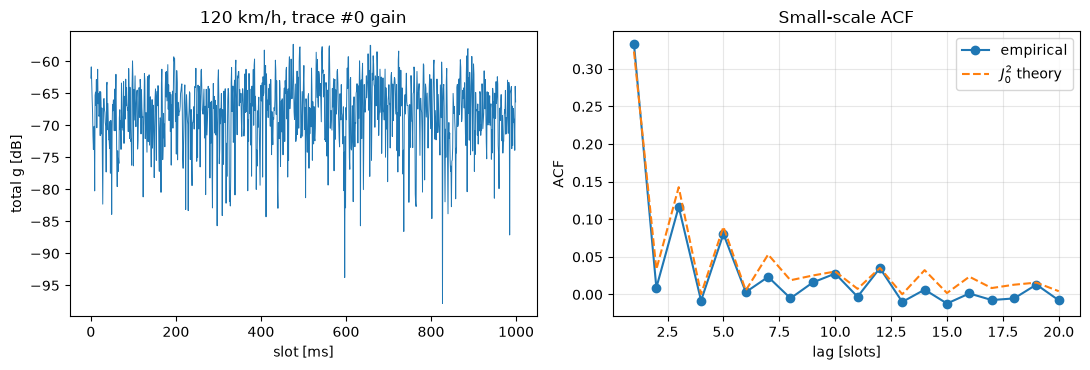

In [4]:
cfg = SceneConfig()
g, d, f_d, g_small = generate_speed(cfg, 120.0, n_traces=20, seed=cfg.seed+10_000)
lags, emp, thy = acf_stats(g_small, f_d, cfg.dt_s)

print(f'f_D = {f_d:.1f} Hz')
print(f'E[g_small] = {g_small.mean():.4f}  (理论 1.0)')
print(f'lag-1 经验 = {emp[0]:+.3f}   J0^2 理论 = {thy[0]:+.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(10*np.log10(g[0]), lw=0.7)
ax[0].set(xlabel='slot [ms]', ylabel='total g [dB]',
          title='120 km/h, trace #0 gain')
ax[1].plot(lags, emp, 'o-', label='empirical')
ax[1].plot(lags, thy, '--', label=r'$J_0^2$ theory')
ax[1].set(xlabel='lag [slots]', ylabel='ACF', title='Small-scale ACF')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. 种子设计、数据契约与用法

### 种子隔离（保证公平对比 + 可复现）

$$\text{seed}=\text{base}+10000\,i+\begin{cases}0,&\text{train}\\5{,}000{,}000,&\text{test}\end{cases}$$

其中 $i$ 是速度序号（0/1/2）。这样：
- 三个速度的随机流互不相同；训练/测试集互不泄漏
- **测试集种子固定** → 均匀 / 注水 / 学习策略在完全相同的 100 条轨迹上评估
- 阴影使用 `seed+1` 的独立生成器，不与 TDL 随机流耦合

### npz 数据契约（下游只依赖这个）

| 字段 | 形状/类型 | 含义 |
|---|---|---|
| `g` | `[N, T]` float32 | 总线性功率增益（路损×阴影×小尺度）|
| `d` | `[T]` float32 | 车–节点距离 [m]，同速度共享 |
| `meta` | dict | 速度、$f_D$、TDL 参数、种子、版本等 |

### 命令行用法

```bash
python channel/sionna_traces.py --quick   # 20+6 条/速度，快速验证
python channel/sionna_traces.py           # 1000+100 条/速度，全量
```

全量约 9 秒（CPU）。产物：`traces/sionna_speed{v}_{train,test}.npz`
与两张 sanity 图（增益时序、ACF 对拍）到 `results/`。